# 05 · Organ temperature stability

**Critical event (brief):** $|T(t_0) - T(t_1)| > 1\,°C$ with $t_1 - t_0 = 1$ hour, on the
organ air temperature. Rapid changes detune the organ and raise maintenance costs.

Implementation (`src/organ.py`): for every reading $t_0$ the partner $T(t_0 + 1\,h)$ is
looked up **by timestamp**. If that reading is missing, no comparison is made – a gap can
never pair readings further apart than one hour. Consecutive event readings are merged
into **episodes**.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src import config as C, load_data as L, results, plotting as P, organ as O
from src.features import heating_season_label

P.setup()
pd.set_option("display.width", 160, "display.max_columns", 30)
df = L.load_processed()
raw = L.load_raw_minimal()
T = df["temp_O1"]
ev = O.detect_events(T)
eps = O.merge_episodes(ev)
print(f"event readings: {len(ev)} | episodes: {len(eps)}")

event readings: 74 | episodes: 23


## 1 · Robustness of the detection

We compare the main method with alternatives:

* **row shift by 3 on raw data after dropping missing rows** – the naive approach: across a
  gap it compares readings that are hours apart;
* time-based lookup on **raw** data (no cleaning at all);
* time-based on clean data **without interpolated values**;
* time-based on clean data (main).

In [2]:
raw_T = raw["temp_O1"]
naive = O.one_hour_change_rowshift(raw_T, dropna=True)
naive_ev = naive[naive.abs() > 1]
s = raw_T.dropna()
span = pd.Series(s.index[3:] - s.index[:-3], index=s.index[:-3])
false_span = (span.reindex(naive_ev.index) != pd.Timedelta("1h")).sum()
no_interp = T.where(~df["flag_interp_O1"])
variants = {
    "row shift (3 rows), raw, missing rows dropped": (naive_ev, None),
    "time-based, raw (no cleaning)": (O.detect_events(raw_T), None),
    "time-based, clean, without interpolated values": (O.detect_events(no_interp), None),
    "time-based, clean (main)": (ev, None),
}
rob = pd.DataFrame({k: {"event readings": len(v[0]),
                        "episodes": len(O.merge_episodes(v[0] if isinstance(v[0], pd.DataFrame) else
                                                         v[0].to_frame("delta").assign(t1=v[0].index + pd.Timedelta("1h"),
                                                                                         direction=np.where(v[0] > 0, "warming", "cooling"))))}
                    for k, v in variants.items()}).T
display(rob)
print(f"naive row shift: {false_span} of its events compare readings that are NOT one hour apart (gap bridged)")
results.save_table(rob, "organ_robustness")

# attribution of the difference raw -> clean
raw_ev = O.detect_events(raw_T)
only_raw = raw_ev.index.difference(ev.index)
cause = pd.Series("other", index=only_raw)
spk = df.index[df["flag_spike_O1"]]
for t in only_raw:
    t1 = t + pd.Timedelta("1h")
    if t < pd.Timestamp("2024-01-20 09:00", tz=C.LOCAL_TZ):
        cause[t] = "installation / relocation"
    elif t in spk or t1 in spk:
        cause[t] = "single-reading glitch"
    elif df["flag_warmup_O1"].reindex([t, t1]).any():
        cause[t] = "warm-up after outage"
print("events in raw data that disappear after cleaning:", cause.value_counts().to_dict())
print("events only in clean data:", len(ev.index.difference(raw_ev.index)))
results.update(organ_events_raw=len(raw_ev), organ_episodes_raw=int(rob.loc["time-based, raw (no cleaning)", "episodes"]),
               organ_events_naive=len(naive_ev), organ_naive_false=int(false_span),
               organ_events_removed_by_cleaning=cause.value_counts().to_dict())

,event readings,episodes
"row shift (3 rows), raw, missing rows dropped",112,38
"time-based, raw (no cleaning)",111,38
"time-based, clean, without interpolated values",71,23
"time-based, clean (main)",74,23


naive row shift: 4 of its events compare readings that are NOT one hour apart (gap bridged)
events in raw data that disappear after cleaning: {'single-reading glitch': 24, 'installation / relocation': 14}
events only in clean data: 1


**Result:** on raw data both the naive and the time-based method find about 111 event
readings in 38 episodes (the brief's preliminary count), and the naive row shift bridges
gaps in 4 cases. **About a third of the raw events are not real**: 24 event readings are
caused by the 14 single-reading glitches (each glitch dip creates a "cooling" and a
"warming" event) and 14 by the installation day and the relocation of the sensor. After
cleaning, 74 event readings in **23 episodes** remain; leaving out interpolated values
changes this by 3 readings and no episode. The result is therefore robust to the method
and to interpolation, but *not* to the cleaning – which is why the glitch rule is
documented carefully in notebook 01.

## 2 · How often?

In [3]:
eps20 = O.merge_episodes(ev, "20min")
thr = pd.DataFrame({t: {"event readings": len(O.detect_events(T, t)), "episodes": len(O.merge_episodes(O.detect_events(T, t)))}
                    for t in [0.5, 0.8, 1.0, 1.2, 1.5, 2.0]}).T
thr.index.name = "threshold (°C per hour)"
print("Sensitivity to the threshold:"); display(thr)

ev["year"] = ev.index.year
ev["season"] = heating_season_label(ev.index).fillna("summer (May-Sep)")
eps["year"] = eps["start"].dt.year
eps["season"] = heating_season_label(pd.DatetimeIndex(eps["start"])).fillna("summer (May-Sep)").values
eps["weekday"] = eps["start"].dt.weekday
eps["hour"] = eps["start"].dt.hour
eps["month"] = eps["start"].dt.month
counts = pd.DataFrame({"event readings": ev.groupby("year").size(), "episodes": eps.groupby("year").size(),
                       "episodes (consecutive rule)": eps20.groupby(eps20.start.dt.year).size()})
print("Per calendar year (2024 from 19 Jan, 2025 until 29 Nov):"); display(counts)
by_season = pd.DataFrame({"event readings": ev.groupby("season").size(), "episodes": eps.groupby("season").size(),
                          "warming": eps[eps.direction == "warming"].groupby("season").size(),
                          "cooling": eps[eps.direction == "cooling"].groupby("season").size(),
                          "mixed": eps[eps.direction == "mixed"].groupby("season").size()}).fillna(0).astype(int)
print("Per heating season (Oct-Apr):"); display(by_season)
dirs = ev.direction.value_counts()
print("event readings by direction:", dirs.to_dict(), "| episodes:", eps.direction.value_counts().to_dict())
display(eps.sort_values("max_abs_delta", ascending=False).head(8)[["start", "end", "n_events", "max_abs_delta", "direction"]])
results.save_table(by_season, "organ_by_season")
results.save_table(eps.drop(columns=["net_delta"]), "organ_episodes")
results.save_table(thr, "organ_threshold_sensitivity")
results.update(organ_events=len(ev), organ_episodes=len(eps), organ_episodes_consecutive=len(eps20),
               organ_warming_events=int(dirs.get("warming", 0)), organ_cooling_events=int(dirs.get("cooling", 0)),
               organ_warming_episodes=int((eps.direction == "warming").sum()),
               organ_episodes_heating_share=float(eps.season.ne("summer (May-Sep)").mean()),
               organ_episodes_by_season={k: int(v) for k, v in by_season["episodes"].items()},
               organ_max_delta=float(eps.max_abs_delta.max()),
               organ_events_08=int(thr.loc[0.8, "episodes"]), organ_events_15=int(thr.loc[1.5, "episodes"]))

Sensitivity to the threshold:


,event readings,episodes
threshold (°C per hour),,
0.5,1441,171
0.8,441,93
1.0,74,23
1.2,25,9
1.5,6,2
2.0,3,1


Per calendar year (2024 from 19 Jan, 2025 until 29 Nov):


,event readings,episodes,episodes (consecutive rule)
2024,39,13,13
2025,35,10,10


Per heating season (Oct-Apr):


,event readings,episodes,warming,cooling,mixed
season,,,,,
2023/24,20,7,7,0,0
2024/25,40,13,13,0,0
2025/26,14,3,3,0,0


event readings by direction: {'warming': 74} | episodes: {'warming': 23}


,start,end,n_events,max_abs_delta,direction
1,2024-02-28 15:20:00+01:00,2024-02-28 17:00:00+01:00,3,2.84,warming
11,2024-12-24 14:20:00+01:00,2024-12-24 17:20:00+01:00,7,1.71,warming
20,2025-11-01 15:40:00+01:00,2025-11-01 17:40:00+01:00,4,1.37,warming
22,2025-11-22 08:40:00+01:00,2025-11-22 11:20:00+01:00,6,1.34,warming
2,2024-03-12 11:00:00+01:00,2024-03-12 12:40:00+01:00,3,1.33,warming
7,2024-11-23 09:20:00+01:00,2024-11-23 11:00:00+01:00,3,1.27,warming
18,2025-03-01 17:40:00+01:00,2025-03-01 19:40:00+01:00,4,1.27,warming
4,2024-03-27 14:40:00+01:00,2024-03-27 16:40:00+01:00,4,1.25,warming


## 3 · When? Month, hour and weekday

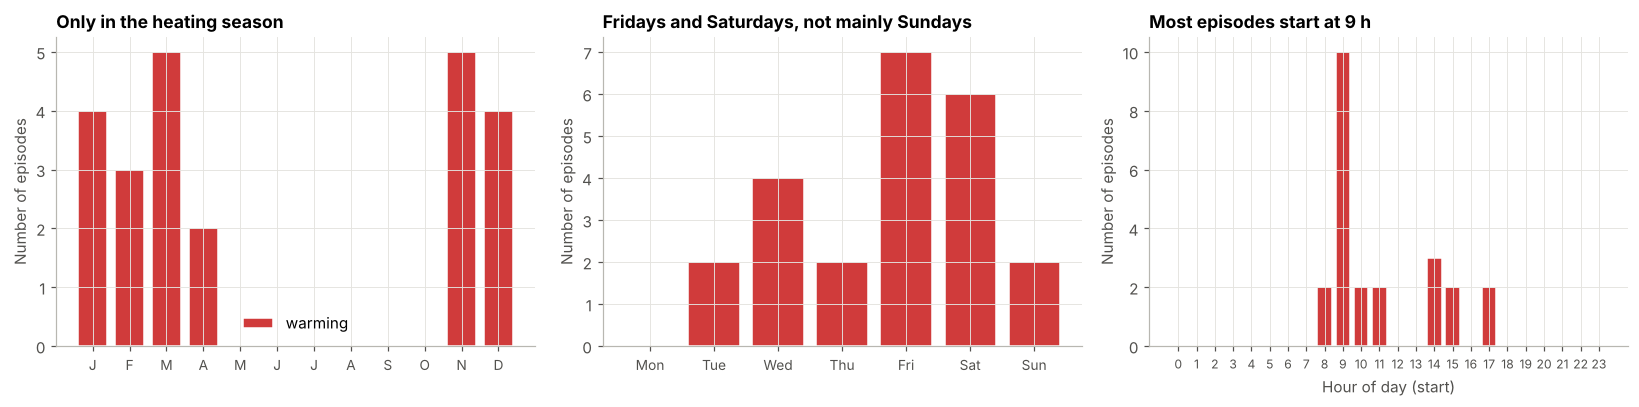

episodes by weekday: {0: 0, 1: 2, 2: 4, 3: 2, 4: 7, 5: 6, 6: 2}


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
m = eps.groupby(["month", "direction"]).size().unstack(fill_value=0).reindex(range(1, 13), fill_value=0)
w = eps.groupby(["weekday", "direction"]).size().unstack(fill_value=0).reindex(range(7), fill_value=0)
h = eps.groupby(["hour", "direction"]).size().unstack(fill_value=0).reindex(range(24), fill_value=0)
cols = {"warming": P.STATUS["high"], "cooling": P.SERIES[0], "mixed": P.SERIES[8]}
for ax, tab, labels, title in [
        (axes[0], m, ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"], "Only in the heating season"),
        (axes[1], w, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], "Fridays and Saturdays, not mainly Sundays"),
        (axes[2], h, [str(i) for i in range(24)], "Most episodes start at 9 h")]:
    bottom = np.zeros(len(tab))
    for d in [c for c in ["warming", "cooling", "mixed"] if c in tab]:
        ax.bar(range(len(tab)), tab[d], bottom=bottom, color=cols[d], label=d, edgecolor="white", linewidth=1)
        bottom += tab[d].values
    ax.set_xticks(range(len(tab)), labels, fontsize=8 if len(tab) > 12 else 9)
    ax.set_title(title); ax.set_ylabel("Number of episodes")
axes[0].legend(); axes[2].set_xlabel("Hour of day (start)")
plt.tight_layout(); P.save(fig, "05_organ_when.png"); plt.show()
print("episodes by weekday:", w.sum(axis=1).to_dict())

## 4 · Why? Heating, outside weather and the rest of the church

In [5]:
# (a) other sensors at the same time: is the whole church changing?
rows = []
for sname in ["K2", "AWs", "AWo", "AWn", "K1", "D1", "Ke1", "AU"]:
    d = O.one_hour_change_time(df[f"temp_{sname}"])
    heat = d.index.month.isin(C.HEATING_MONTHS)
    rows.append({"location": P.name(sname),
                 "mean |1 h change| during organ events (°C)": d.reindex(ev.index).abs().mean(),
                 "mean |1 h change| otherwise, heating season (°C)": d[heat & ~d.index.isin(ev.index)].abs().mean(),
                 "valid event readings": int(d.reindex(ev.index).notna().sum())})
ctx = pd.DataFrame(rows).set_index("location").round(2)
display(ctx)
results.save_table(ctx, "organ_context")

# (b) outside temperature at events vs normal heating-season hours
heat_idx = df.index.month.isin(C.HEATING_MONTHS)
out_ev = df["temp_AU"].reindex(ev.index)
print(f"outside temp during events: median {out_ev.median():.1f} °C vs heating season overall {df.loc[heat_idx, 'temp_AU'].median():.1f} °C")
print(f"organ temp at event start: median {T.reindex(ev.index).median():.1f} °C vs heating season {T[heat_idx].median():.1f} °C")
print(f"inside - outside at event start: median {(T - df['temp_AU']).reindex(ev.index).median():.1f} °C")

,mean |1 h change| during organ events (°C),"mean |1 h change| otherwise, heating season (°C)",valid event readings
location,,,
Art objects S,1.55,0.48,74
South wall,1.20,0.12,34
East wall,1.37,0.14,34
North wall,1.72,0.19,16
Art objects NW,0.30,0.05,57
Attic,0.64,0.51,64
Basement,0.02,0.03,62
Outside,0.66,0.44,73


outside temp during events: median 6.9 °C vs heating season overall 8.8 °C
organ temp at event start: median 10.4 °C vs heating season 11.9 °C
inside - outside at event start: median 3.7 °C


warming episodes: median total rise within 8 h 2.6 °C, median max 1-h rise 1.17 °C


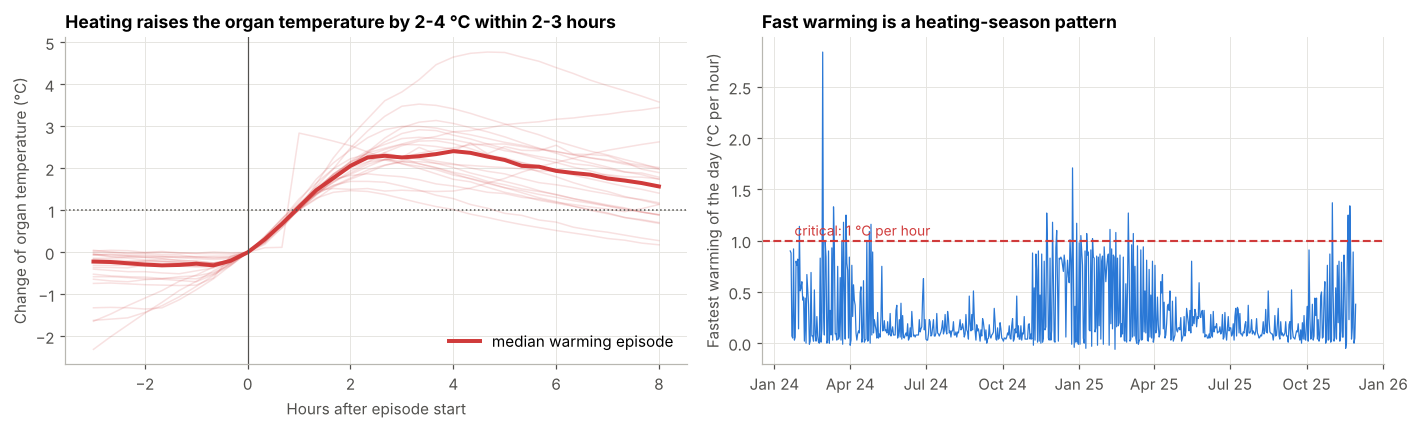

In [6]:
# (c) average course of the organ temperature around the start of warming episodes
warm = eps[eps.direction == "warming"]
win = pd.timedelta_range("-3h", "8h", freq="20min")
traj = []
for t in warm["start"]:
    v = T.reindex(t + win).to_numpy()
    traj.append(v - v[9])  # relative to t0
traj = np.array(traj)
cool_traj = []
for t in eps[eps.direction == "cooling"]["start"]:
    v = T.reindex(t + win).to_numpy(); cool_traj.append(v - v[9])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hours = win / pd.Timedelta("1h")
ax = axes[0]
for row in traj:
    ax.plot(hours, row, color=P.STATUS["high"], alpha=0.15, lw=1)
ax.plot(hours, np.nanmedian(traj, axis=0), color=P.STATUS["high"], lw=2.6, label="median warming episode")
if len(cool_traj):
    ax.plot(hours, np.nanmedian(np.array(cool_traj), axis=0), color=P.SERIES[0], lw=2.2,
            label=f"median cooling episode (n={len(cool_traj)})")
ax.axhline(1, color=P.INK2, ls=":", lw=1); ax.axvline(0, color=P.INK2, lw=0.8)
ax.set_xlabel("Hours after episode start"); ax.set_ylabel("Change of organ temperature (°C)")
ax.set_title("Heating raises the organ temperature by 2-4 °C within 2-3 hours")
ax.legend()
rise = np.nanmax(traj[:, 9:], axis=1)
print(f"warming episodes: median total rise within 8 h {np.nanmedian(rise):.1f} °C, "
      f"median max 1-h rise {warm.max_abs_delta.median():.2f} °C")

# (d) heating-day profile: daily maximum hourly rise vs number of hours needed at 0.5 °C/h
d1h = O.one_hour_change_time(T)
dmax = d1h.groupby(d1h.index.date).max()
dmax.index = pd.to_datetime(dmax.index)
ax = axes[1]
ax.plot(dmax.index, dmax, lw=0.8, color=P.SERIES[0])
ax.axhline(1, color=P.STATUS["high"], ls="--", lw=1.4)
ax.text(dmax.index[5], 1.05, "critical: 1 °C per hour", color=P.STATUS["high"], fontsize=9)
ax.set_ylabel("Fastest warming of the day (°C per hour)")
ax.set_title("Fast warming is a heating-season pattern")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
plt.tight_layout(); P.save(fig, "05_organ_why.png"); plt.show()
results.update(organ_warm_rise_median=float(np.nanmedian(rise)),
               organ_warm_rate_median=float(warm.max_abs_delta.median()),
               organ_out_temp_events=float(out_ev.median()),
               organ_ctx_south_wall=float(ctx.loc[P.name("AWs"), "mean |1 h change| during organ events (°C)"]),
               organ_ctx_south_wall_norm=float(ctx.loc[P.name("AWs"), "mean |1 h change| otherwise, heating season (°C)"]))

### Near misses and the organ case surface

How close does the organ get to the limit, and what does the surface sensor on the organ
see? (The case and pipes follow the air more slowly.)

In [7]:
heat_d = d1h[d1h.index.month.isin(C.HEATING_MONTHS)]
near = pd.DataFrame({"share of heating-season hours with |change| > 0.5 °C": [(heat_d.abs() > 0.5).mean()],
                     "> 0.8 °C": [(heat_d.abs() > 0.8).mean()], "> 1.0 °C": [(heat_d.abs() > 1.0).mean()]}).round(4)
display(near)
surf_ev = O.detect_events(df["surf_temp_O1"])
print(f"events on the organ SURFACE temperature: {len(surf_ev)} readings, {len(O.merge_episodes(surf_ev))} episodes")
results.update(organ_surface_events=len(surf_ev), organ_surface_episodes=len(O.merge_episodes(surf_ev)),
               organ_near_08=float((heat_d.abs() > 0.8).mean()))

,share of heating-season hours with |change| > 0.5 °C,> 0.8 °C,> 1.0 °C
0,0.0531,0.0164,0.0028


events on the organ SURFACE temperature: 0 readings, 0 episodes


## 5 · What this means for the parish

* From January 2024 to November 2025 the organ air temperature changed by more than 1 °C
  within one hour in **23 episodes** (74 readings): 7 in the heating season 2023/24 (from
  19 Jan), 13 in 2024/25 and 3 so far in 2025/26. **All of them are warming episodes and all
  occur in the heating season** – none in summer, and no rapid cooling at all.
* They are **heating starts**: during the episodes the south, east and north walls warm
  about ten times faster than usual, while the basement does not react. Outside it is
  slightly colder than usual (median 6.9 °C vs 8.8 °C) and the organ starts from a lower
  temperature (10.4 °C vs 11.9 °C), so the heating has more to do.
* They do **not** mainly occur on Sunday mornings (only 2 of 23), but on **Fridays (7)
  and Saturdays (6)**. Six Friday episodes between January and March 2025 start at
  exactly 9:00–9:20 → a regular Friday-morning event (e.g. a school or weekday service)
  that is heated quickly. Other episodes fit weddings / funerals / concerts on Saturdays
  and Christmas Eve (24 Dec 2024, the second-largest episode).
* A typical heating start raises the organ by about 2.6 °C, with a peak rate just above
  1 °C per hour (median 1.17 °C/h). The organ's surface sensor never changes by more than
  1 °C per hour: the instrument's mass is slower than the air, but the air in the pipes
  decides the pitch.
* Near misses are frequent: with 0.8 °C instead of 1 °C there would be 93 episodes. Small
  changes to the heating schedule therefore have a large effect.
* **Recommendation:** program *every* heating start – especially the regular Friday
  morning and Saturday events, not only Sunday – to begin earlier and ramp gently: a rise
  of 2.6 °C at ≤ 0.5 °C per hour needs about 5–6 hours instead of 2–3. Keep a moderate
  base temperature in winter so that the rise needed is smaller, and add an alert
  ("organ air rose by more than 0.8 °C in the last hour").